# Weather and Demand Extrapolation 
Uses full year 12-hour data for extrapolation of the three weeks of 1-min data. This results in a full year 1-min approximation of the weather data.

## Initialization

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pvlib.location import Location
from pvlib.irradiance import get_total_irradiance

In [55]:
DATA = 'A'

# Irradiance Interpolation Parameters
NOISE_INTENSITY = 0.5
SMOOTHING_WINDOW = 10

# Temperature Interpolation Parameters
AMPLITUDE_FACTOR = 2.0

## Load Data

In [56]:
# === WEATHER DATA ===
# Load 1-min weather data
df_weather_1min = pd.read_csv(f'Data/Munich_weather_1min.csv')

# Rename frst colum to timestamp and set as index in df_weather_1min
df_weather_1min['timestamp'] = df_weather_1min['Unnamed: 0']
df_weather_1min = df_weather_1min.drop(columns=['Unnamed: 0'])
df_weather_1min['timestamp'] = pd.to_datetime(df_weather_1min['timestamp'])
df_weather_1min.set_index('timestamp', inplace=True)

# Load 12-hourly weather data
df_weather_12h = pd.read_csv(f'Data/Munich_weather_12h.csv')
# Remove Unnamed: 0 column from df_weather_12h and df_weather_1min
df_weather_12h = df_weather_12h.drop(columns=['Unnamed: 0'])

# Add timestamp colum to df_weather_12h starting from '2013-01-01 00:00:00' with frequency of 12 hours
df_weather_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_weather_12h), freq='12h')
df_weather_12h['timestamp'] = pd.to_datetime(df_weather_12h['timestamp'])
df_weather_12h.set_index('timestamp', inplace=True)

# === DEMAND DATA ===
# Load 1-minute demand data
df_demand_1min = pd.read_csv(f"Data/hh_demand_true_{DATA}.csv")

if DATA == 'A':
    # Add timestamp column with 1-minute frequency for full year
    df_demand_1min['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_demand_1min), freq='min')
    df_demand_1min.set_index('timestamp', inplace=True)

    # Filter to keep only three specific weeks to match Munich_weather_1min
    weeks = [
        ('2013-01-10 00:00:00', '2013-01-16 23:59:00'),
        ('2013-04-10 00:00:00', '2013-04-16 23:59:00'),
        ('2013-07-10 00:00:00', '2013-07-16 23:59:00')
    ]

    # Create a mask for the three weeks
    mask = pd.Series(False, index=df_demand_1min.index)
    for start, end in weeks:
        mask |= (df_demand_1min.index >= start) & (df_demand_1min.index <= end)

    # Apply the filter
    df_demand_1min = df_demand_1min[mask]

    print(f"Filtered demand data to {len(df_demand_1min)} rows across {len(weeks)} weeks")
# For Dataset B, where we already will have only three weeks of 1-minute data
else:
    # Use first column as timestamp, similar to cell 2
    df_demand_1min['timestamp'] = df_demand_1min['Unnamed: 0']
    df_demand_1min = df_demand_1min.drop(columns=['Unnamed: 0'])
    df_demand_1min['timestamp'] = pd.to_datetime(df_demand_1min['timestamp'])
    df_demand_1min.set_index('timestamp', inplace=True)

df_demand_1min.head()

Filtered demand data to 30240 rows across 3 weeks


,Load
timestamp,
2013-01-10 00:00:00,0.037363
2013-01-10 00:01:00,0.046175
2013-01-10 00:02:00,0.046085
2013-01-10 00:03:00,0.029880
2013-01-10 00:04:00,0.040711


## Irradiance Intrapolation
The available full year 12-hour data is intrapolated using the 1-min data as a reference and clear sky POA irradiance to achieve characteristic intra-day behavior of the sun.

As the location of the measurements were unknown, the TUM Campus in Munich was chosen.

### Generate Synthetic POA Irradiance

In [57]:
# 1. CONFIGURATION
#  Location (Munich Campus)
lat, lon = 48.14904043542013, 11.567681331388638
altitude = 519 
#tz = 'Europe/Berlin'

# PV Panel Orientation
surface_tilt = 30 
surface_azimuth = 180  # (south)

# Define the full year time index (1-minute resolution)
times = pd.date_range(start='2013-01-01 00:00:00', end='2013-12-31 23:59:00', freq='1min')

# 2. GENERATE REFERENCE CLEAR SKY POA
# Define Location
site = Location(lat, lon, altitude=altitude, name='Munich Campus')

# Calculate solar position
solar_position = site.get_solarposition(times)

# Calculate Clear Sky GHI/DNI/DHI
cs = site.get_clearsky(times)

# Transpose Clear Sky Data to Plane of Array (POA)
cs_poa = get_total_irradiance(
    surface_tilt,
    surface_azimuth,
    solar_position['apparent_zenith'],
    solar_position['azimuth'],
    cs['dni'],
    cs['ghi'],
    cs['dhi']
)

# We only care about the total radiation 
reference_poa = cs_poa['poa_global']

# Shift to match timezone of weather data
reference_poa = reference_poa.shift(60)  # Shift by 1 hours for Europe/Berlin
reference_poa = reference_poa.fillna(0)

# Delete last hour to match length of weather data
ref_poa = reference_poa[:-60]


# 3. DOWNSCALING RADIATION (Stochastic Method)

# Resample reference to 12h to match input data
ref_12h = ref_poa.resample('12h', label='left').mean()

# Calculate Clearness Index
df_combined = pd.concat([df_weather_12h['G_Gk'], ref_12h], axis=1)

# If Reference is 0, Kt is 0
df_combined['Kt'] = df_combined['G_Gk'] / df_combined['poa_global'].replace(0, np.nan)
df_combined['Kt'] = df_combined['Kt'].fillna(0).clip(0, 1.2)

# Upsample Kt to 1-minute resolution using linear interpolation
Kt_1min = df_combined['Kt'].reindex(times).interpolate(method='linear')

# Apply Base Calculation (Reference * Kt)
poa_1min = ref_poa * Kt_1min

# Add Stochastic Noise (Clouds)
# Only apply noise during daylight and when Kt indicates clouds
daylight_mask = (ref_poa > 10)
cloudy_mask = (Kt_1min > 0.2) & (Kt_1min < 0.9)

# Generate noise
noise_scale = NOISE_INTENSITY * (1 - abs(Kt_1min - 0.5) * 2)
random_noise = np.random.normal(0, 1, size=len(times))

# Smooth the noise (clouds dont flicker instantly every minute)
smoothed_noise = pd.Series(random_noise, index=times).rolling(SMOOTHING_WINDOW, min_periods=1, center=True).mean()

# Apply noise 
final_poa = poa_1min.copy()
final_poa[daylight_mask & cloudy_mask] *= (1 + smoothed_noise[daylight_mask & cloudy_mask] * noise_scale[daylight_mask & cloudy_mask])

# Final Cleanup
final_poa = final_poa.clip(lower=0)
final_poa = final_poa.to_frame(name='poa_global')

### Plot Irradiance Comparison for one week

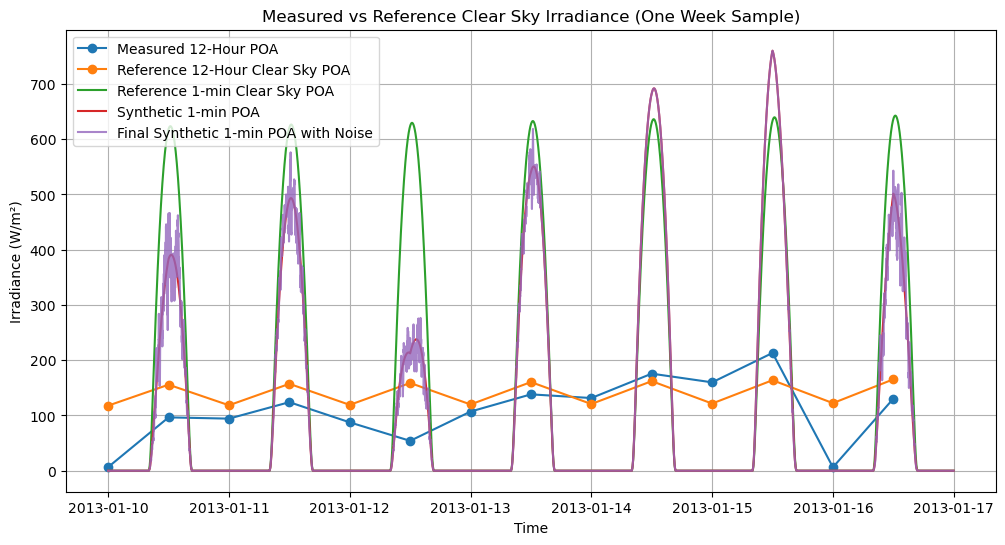

In [58]:
# Only plot one week for clarity
mask = (df_combined.index >= '2013-01-10') & (df_combined.index < '2013-01-17')
mask_1min = (poa_1min.index >= '2013-01-10 00:00:00') & (poa_1min.index < '2013-01-17 00:00:00')
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[mask], df_combined.loc[mask, 'G_Gk'], label='Measured 12-Hour POA', marker='o')
plt.plot(df_combined.index[mask], df_combined.loc[mask, 'poa_global'], label='Reference 12-Hour Clear Sky POA', marker='o')
plt.plot(reference_poa.index[mask_1min], reference_poa[mask_1min], label='Reference 1-min Clear Sky POA')
plt.plot(poa_1min.index[mask_1min], poa_1min[mask_1min], label='Synthetic 1-min POA')
plt.plot(final_poa.index[mask_1min], final_poa[mask_1min], label='Final Synthetic 1-min POA with Noise', alpha=0.8)
plt.xlabel('Time') 
plt.ylabel('Irradiance (W/m²)')
plt.title('Measured vs Reference Clear Sky Irradiance (One Week Sample)')
plt.legend()
plt.grid()
plt.show()

### Compare synthetic 1-min Irradiance to real 1-min Irradiance

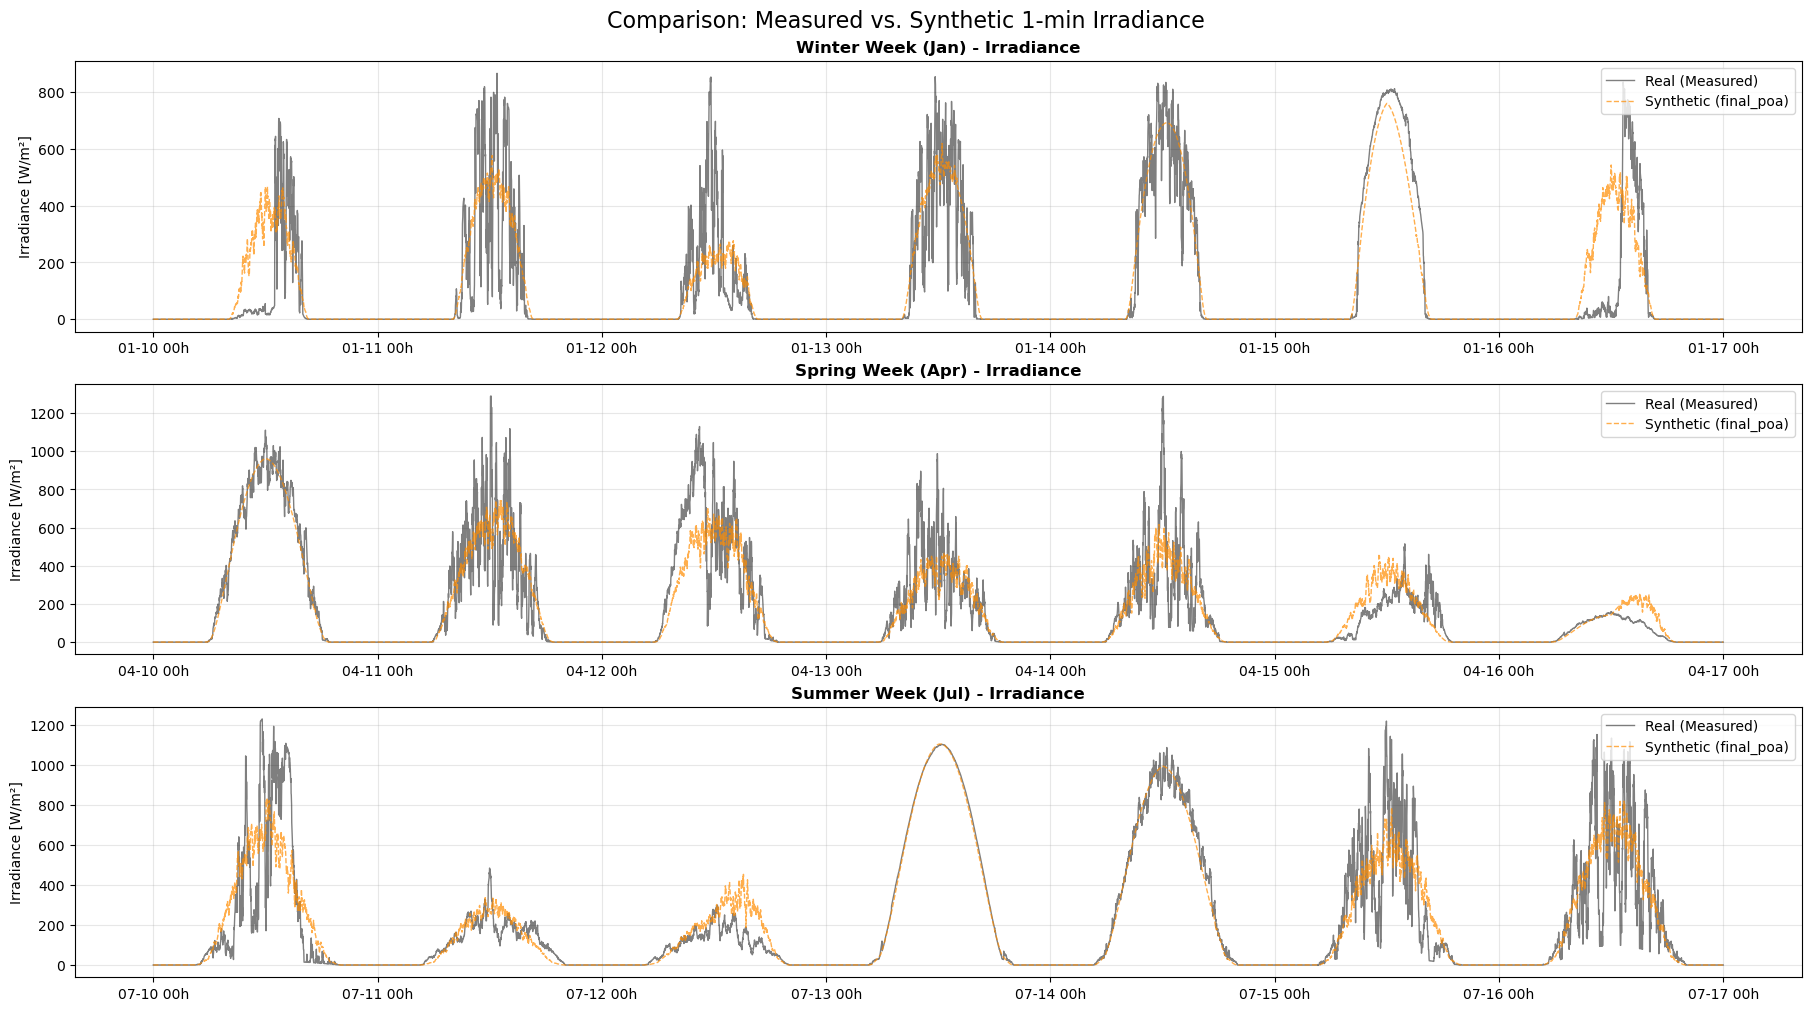

In [59]:
# Define 3 representative weeks (Winter, Spring, Summer)
weeks = [
    ('2013-01-10', '2013-01-16', 'Winter Week (Jan)'),
    ('2013-04-10', '2013-04-16', 'Spring Week (Apr)'),
    ('2013-07-10', '2013-07-16', 'Summer Week (Jul)')
]

# --- PLOTTING ---
# Create a 3x1 grid (3 Weeks rows x 1 Metric column)
fig, axes = plt.subplots(3, 1, figsize=(18, 10), constrained_layout=True, sharex=False)

for i, (start, end, label) in enumerate(weeks):
    # Slice the dataframes for the specific week
    # We use .loc[start:end] to slice by index (DatetimeIndex)
    real_slice = df_weather_1min.loc[start:end]
    synth_slice = final_poa.loc[start:end]

    # --- IRRADIANCE COMPARISON ---
    ax_rad = axes[i]

    # Plot Real Data (Black/Grey for Ground Truth)
    ax_rad.plot(real_slice.index, real_slice['G_Gk'],
                color='black', alpha=0.5, linewidth=1, label='Real (Measured)')

    # Plot Synthetic Data (Orange for Simulation)
    ax_rad.plot(synth_slice.index, synth_slice,
                color='darkorange', alpha=0.7, linewidth=1, linestyle='--', label='Synthetic (final_poa)')

    ax_rad.set_title(f"{label} - Irradiance", fontsize=12, fontweight='bold')
    ax_rad.set_ylabel("Irradiance [W/m²]")
    ax_rad.legend(loc='upper right', frameon=True)
    ax_rad.grid(True, alpha=0.3)

    # Date Formatting for X-Axis
    date_fmt = mdates.DateFormatter('%m-%d %Hh')
    ax_rad.xaxis.set_major_formatter(date_fmt)

# Main Title
fig.suptitle('Comparison: Measured vs. Synthetic 1-min Irradiance', fontsize=16)
plt.show()

## Temperature Interpolation

The available 12-hour data is intrapolated using the given 1-min data as a reference. The Pchip method is used for interpolation.

### Generate Synthetic Temperatures

In [60]:
# 1. SHIFT AND PREPARE TEMPERATURE DATA
df_temp_centered = df_weather_12h[['Ta']].copy()

# Shift the index forward by 3 hours
# 00:00 becomes 03:00, 12:00 becomes 15:00
df_temp_centered.index = df_temp_centered.index + pd.Timedelta(hours=3)

# 2. DOWNSCALE TEMPERATURE (With Amplitude Boost) ---

# Standard Interpolation
temp_base = df_temp_centered['Ta'].reindex(times).interpolate(method='pchip', limit_direction='both')

# Amplitude Correction
# We calculate the rolling 24h mean to find the "center" of the day
temp_rolling_mean = temp_base.rolling(window=1440, center=True, min_periods=1).mean()

# Calculate the deviation from the mean and multiply it by our factor
temp_stretched = temp_rolling_mean + (temp_base - temp_rolling_mean) * AMPLITUDE_FACTOR

# 3. Add tiny thermal noise for texture
temp_final = temp_stretched + np.random.normal(0, 0.05, len(times))

# --- 6. EXPORT ---
df_result = pd.DataFrame({
    'POA_Global_Wm2': final_poa['poa_global'],
    'T_Ambient_C': temp_final
}, index=times)

print(df_result.head())

                     POA_Global_Wm2  T_Ambient_C
2013-01-01 00:00:00             0.0     0.681026
2013-01-01 00:01:00             0.0     0.717539
2013-01-01 00:02:00             0.0     0.820184
2013-01-01 00:03:00             0.0     0.779285
2013-01-01 00:04:00             0.0     0.912187


### Compare synthetic 1-min Temperature to real 1-min Temperature

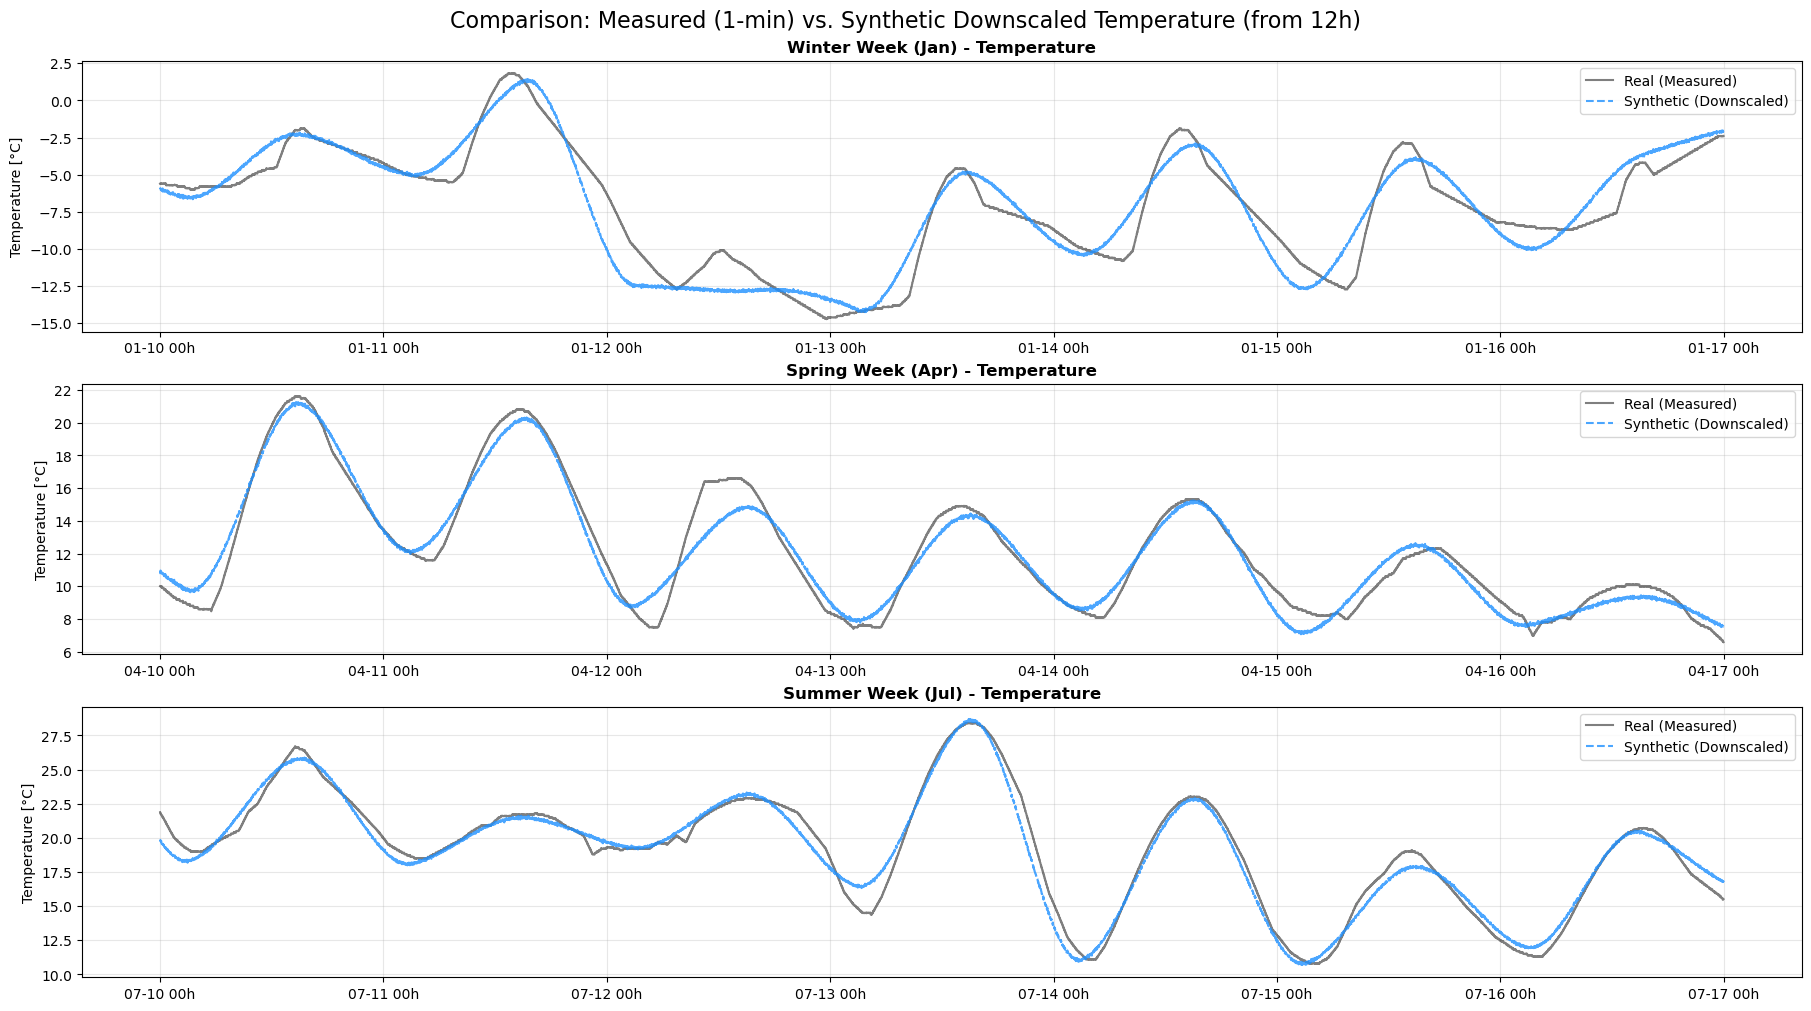

In [61]:
# --- CONFIGURATION ---
# Define the column names for your REAL dataframe
col_temp_real = 'Ta'    # Replace if your column name is different

# Define the column names for the SYNTHETIC dataframe (from previous step)
col_temp_synth = 'T_Ambient_C'

# Define 3 representative weeks (Winter, Spring, Summer)
# Format: (Start_Date, End_Date, Title_Label)
weeks = [
    ('2013-01-10', '2013-01-16', 'Winter Week (Jan)'),
    ('2013-04-10', '2013-04-16', 'Spring Week (Apr)'),
    ('2013-07-10', '2013-07-16', 'Summer Week (Jul)')
]

# --- PLOTTING ---
# Create a 3x1 grid (3 rows x 1 column for temperature comparison)
fig, axes = plt.subplots(3, 1, figsize=(18, 10), constrained_layout=True)

for i, (start, end, label) in enumerate(weeks):
    # Slice the dataframes for the specific week
    # We use .loc[start:end] to slice by index (DatetimeIndex)
    real_slice = df_weather_1min.loc[start:end]
    synth_slice = df_result.loc[start:end]
    
    # --- TEMPERATURE COLUMN ---
    ax_temp = axes[i]
    
    # Plot Real Data
    ax_temp.plot(real_slice.index, real_slice[col_temp_real], 
                 color='black', alpha=0.5, linewidth=1.5, label='Real (Measured)')
    
    # Plot Synthetic Data
    ax_temp.plot(synth_slice.index, synth_slice[col_temp_synth], 
                 color='dodgerblue', alpha=0.8, linewidth=1.5, linestyle='--', label='Synthetic (Downscaled)')
    
    ax_temp.set_title(f"{label} - Temperature", fontsize=12, fontweight='bold')
    ax_temp.set_ylabel("Temperature [°C]")
    ax_temp.legend(loc='upper right', frameon=True)
    ax_temp.grid(True, alpha=0.3)
    
    # Date Formatting for X-Axis
    date_fmt = mdates.DateFormatter('%m-%d %Hh')
    ax_temp.xaxis.set_major_formatter(date_fmt)

# Main Title
fig.suptitle('Comparison: Measured (1-min) vs. Synthetic Downscaled Temperature (from 12h)', fontsize=16)

# Save or Show
# plt.savefig('Comparison_Real_vs_Synthetic.png', dpi=300)
plt.show()

## Demand intrapolation

In [62]:
# Verify the filtered demand data date ranges
print("Demand data (df_demand_1min):")
print(f"Start: {df_demand_1min.index.min()}")
print(f"End: {df_demand_1min.index.max()}")
print(f"Total rows: {len(df_demand_1min)}")

# Show the date ranges for each week
if DATA == 'A':
    print("\nData points per week:")
    for start, end, _ in weeks:
        week_mask = (df_demand_1min.index >= start) & (df_demand_1min.index <= end)
        print(f"{start} to {end}: {week_mask.sum()} rows")

Demand data (df_demand_1min):
Start: 2013-01-10 00:00:00
End: 2013-07-16 23:59:00
Total rows: 30240

Data points per week:
2013-01-10 to 2013-01-16: 8641 rows
2013-04-10 to 2013-04-16: 8641 rows
2013-07-10 to 2013-07-16: 8641 rows


In [63]:
df_demand_12h = pd.read_csv(f"Data/hh_demand_12h_{DATA}.csv")
# Add timestamp column starting from '2013-01-01 00:00:00' with 12-hour frequency
# (same logic as weather data)
df_demand_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_demand_12h), freq='12h')
df_demand_12h['timestamp'] = pd.to_datetime(df_demand_12h['timestamp'])
df_demand_12h.set_index('timestamp', inplace=True)
df_demand_12h.head()

,Load
timestamp,
2013-01-01 00:00:00,0.219928
2013-01-01 12:00:00,0.285546
2013-01-02 00:00:00,0.201714
2013-01-02 12:00:00,0.233794
2013-01-03 00:00:00,0.092220


In [ ]:
# --- DEMAND EXTRAPOLATION USING PATTERN MATCHING ---
# Instead of generating noise, reuse actual 1-minute patterns from the 3-week data
# scaled to match the 12-hour averages

# 1. LOAD AND PREPARE FULL-YEAR 12-HOUR DEMAND DATA
df_demand_12h = pd.read_csv(f'Data/hh_demand_12h_{DATA}.csv')
df_demand_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_demand_12h), freq='12h')
df_demand_12h.set_index('timestamp', inplace=True)

# 2. BUILD PATTERN LIBRARY FROM 3-WEEK DATA
# Extract all 12-hour chunks from the 3-week 1-minute data
demand_1min_data = df_demand_1min.iloc[:, 0]  # Get the demand column

# Split 3-week data into 12-hour chunks (720 minutes each)
chunk_size = 720  # 12 hours * 60 minutes
pattern_library = []
pattern_means = []

for i in range(0, len(demand_1min_data) - chunk_size + 1, chunk_size):
    chunk = demand_1min_data.iloc[i:i+chunk_size].values
    chunk_mean = chunk.mean()
    if chunk_mean > 0:  # Only store valid patterns
        pattern_library.append(chunk)
        pattern_means.append(chunk_mean)

pattern_means = np.array(pattern_means)
print(f"Built pattern library with {len(pattern_library)} 12-hour patterns")
print(f"Pattern mean range: {pattern_means.min():.4f} to {pattern_means.max():.4f} kW")

# 3. MATCH AND SCALE PATTERNS FOR FULL YEAR
times_full_year = pd.date_range(start='2013-01-01 00:00:00', end='2013-12-31 23:59:00', freq='min')
demand_1min_full_year = np.zeros(len(times_full_year))

# Process each 12-hour period in the full year
num_periods = len(df_demand_12h)
print(f"Processing {num_periods} 12-hour periods...")

for idx in range(num_periods):
    target_mean = df_demand_12h.iloc[idx, 0]
    
    # Find the closest matching pattern from the library
    # (pattern with similar average demand)
    if len(pattern_means) > 0:
        closest_idx = np.argmin(np.abs(pattern_means - target_mean))
        base_pattern = pattern_library[closest_idx]
        pattern_mean = pattern_means[closest_idx]
        
        # Scale the pattern to match the target mean
        if pattern_mean > 0:
            scaled_pattern = base_pattern * (target_mean / pattern_mean)
        else:
            scaled_pattern = base_pattern
        
        # Insert into full year array
        start_idx = idx * chunk_size
        end_idx = min(start_idx + chunk_size, len(demand_1min_full_year))
        demand_1min_full_year[start_idx:end_idx] = scaled_pattern[:end_idx-start_idx]

# 4. CREATE RESULT DATAFRAME
df_demand_1min_fullYear = pd.DataFrame({
    'Demand_kW': demand_1min_full_year
}, index=times_full_year)

print("\nFull-year 1-minute demand created using pattern matching!")
print(f"Shape: {df_demand_1min_fullYear.shape}")
print(f"Mean: {df_demand_1min_fullYear['Demand_kW'].mean():.4f} kW")
print(f"Std: {df_demand_1min_fullYear['Demand_kW'].std():.4f} kW")
print("\nFirst 5 rows:")
print(df_demand_1min_fullYear.head())
print("\nLast 5 rows:")
print(df_demand_1min_fullYear.tail())

Built pattern library with 42 12-hour patterns
Pattern mean range: 0.0755 to 0.4112 kW
Processing 730 12-hour periods...

Full-year 1-minute demand created using pattern matching!
Shape: (525600, 1)
Mean: 0.1808 kW
Std: 0.3466 kW

First 5 rows:
                     Demand_kW
2013-01-01 00:00:00   0.028659
2013-01-01 00:01:00   0.008738
2013-01-01 00:02:00   0.018415
2013-01-01 00:03:00   0.012383
2013-01-01 00:04:00   0.018477

Last 5 rows:
                     Demand_kW
2013-12-31 23:55:00   0.130010
2013-12-31 23:56:00   0.144304
2013-12-31 23:57:00   0.137257
2013-12-31 23:58:00   0.131303
2013-12-31 23:59:00   0.197277


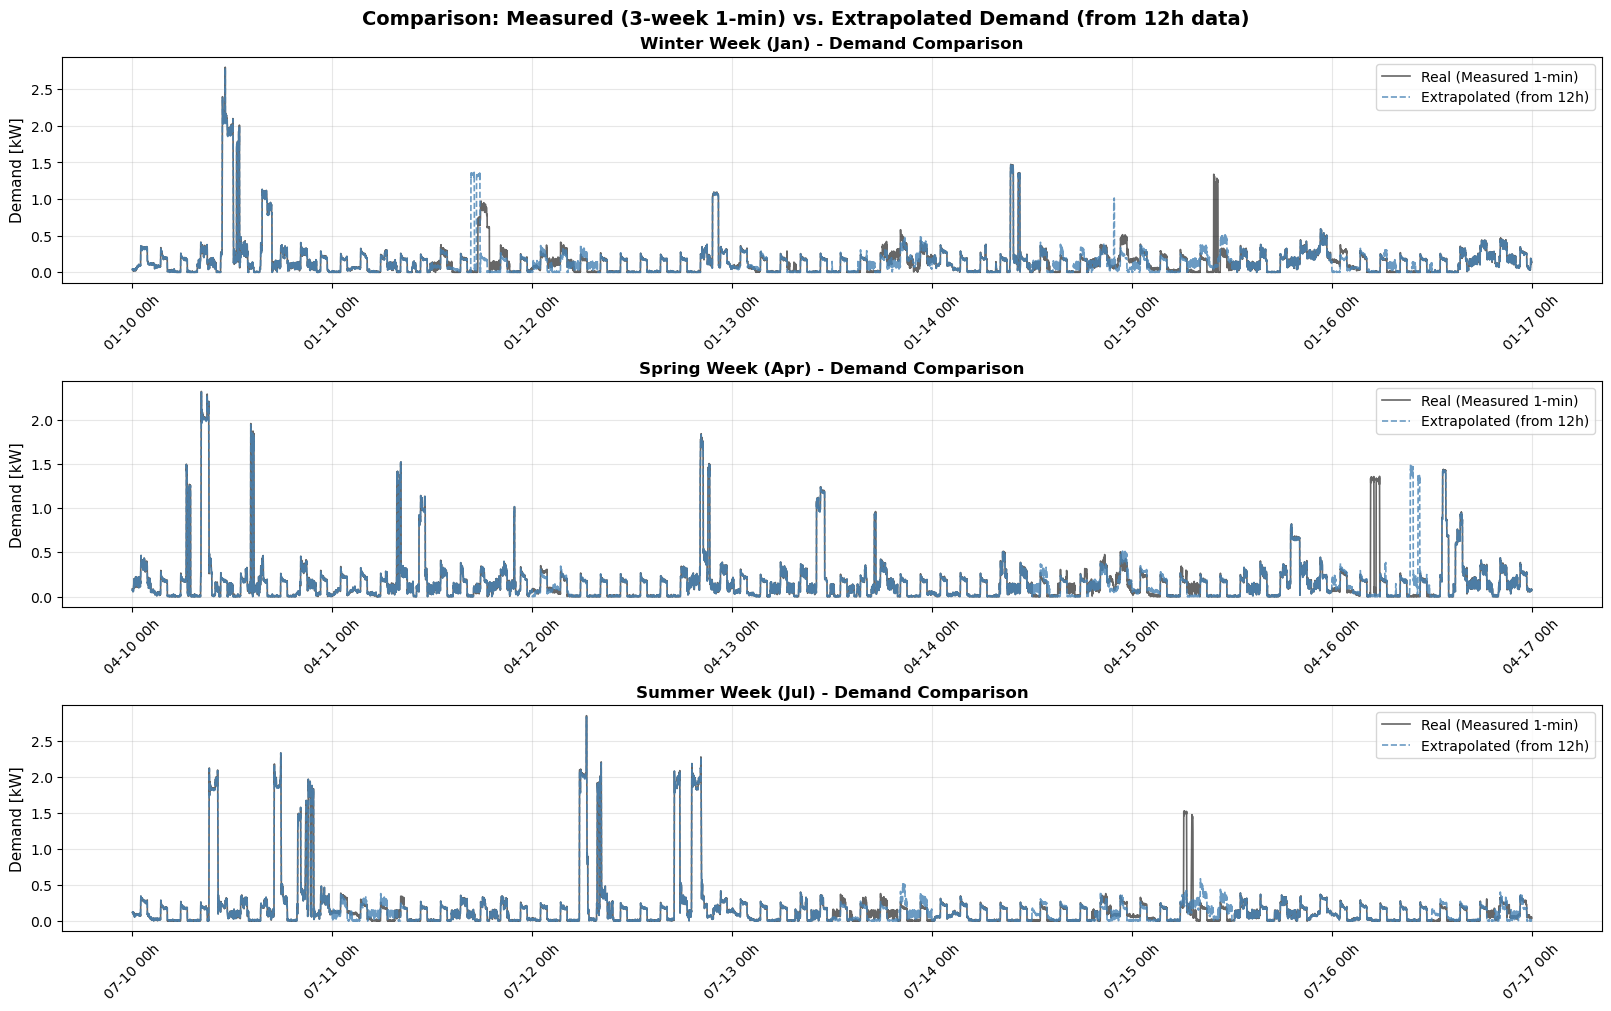

In [65]:
# --- COMPARE REAL 1-MIN DEMAND VS EXTRAPOLATED DEMAND (3 WEEKS) ---
import matplotlib.dates as mdates

# Define 3 representative weeks (same as weather comparison)
weeks_demand = [
    ('2013-01-10', '2013-01-16', 'Winter Week (Jan)'),
    ('2013-04-10', '2013-04-16', 'Spring Week (Apr)'),
    ('2013-07-10', '2013-07-16', 'Summer Week (Jul)')
]

# Create a 3x1 grid (3 weeks)
fig, axes = plt.subplots(3, 1, figsize=(16, 10), constrained_layout=True)

for i, (start, end, label) in enumerate(weeks_demand):
    ax = axes[i]
    
    # Slice the real 1-minute demand (3-week data)
    real_demand_slice = df_demand_1min.loc[start:end]
    
    # Slice the extrapolated full-year demand
    extrapolated_demand_slice = df_demand_1min_fullYear.loc[start:end]
    
    # Plot Real Data (Black for Ground Truth)
    ax.plot(real_demand_slice.index, real_demand_slice.iloc[:, 0], 
            color='black', alpha=0.6, linewidth=1.2, label='Real (Measured 1-min)')
    
    # Plot Extrapolated Data (Blue for Synthetic)
    ax.plot(extrapolated_demand_slice.index, extrapolated_demand_slice['Demand_kW'], 
            color='steelblue', alpha=0.8, linewidth=1.2, linestyle='--', label='Extrapolated (from 12h)')
    
    ax.set_title(f"{label} - Demand Comparison", fontsize=12, fontweight='bold')
    ax.set_ylabel("Demand [kW]", fontsize=11)
    ax.legend(loc='upper right', frameon=True)
    ax.grid(True, alpha=0.3)
    
    # Date Formatting for X-Axis
    date_fmt = mdates.DateFormatter('%m-%d %Hh')
    ax.xaxis.set_major_formatter(date_fmt)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

# Main Title
fig.suptitle('Comparison: Measured (3-week 1-min) vs. Extrapolated Demand (from 12h data)', fontsize=14, fontweight='bold')

plt.show()

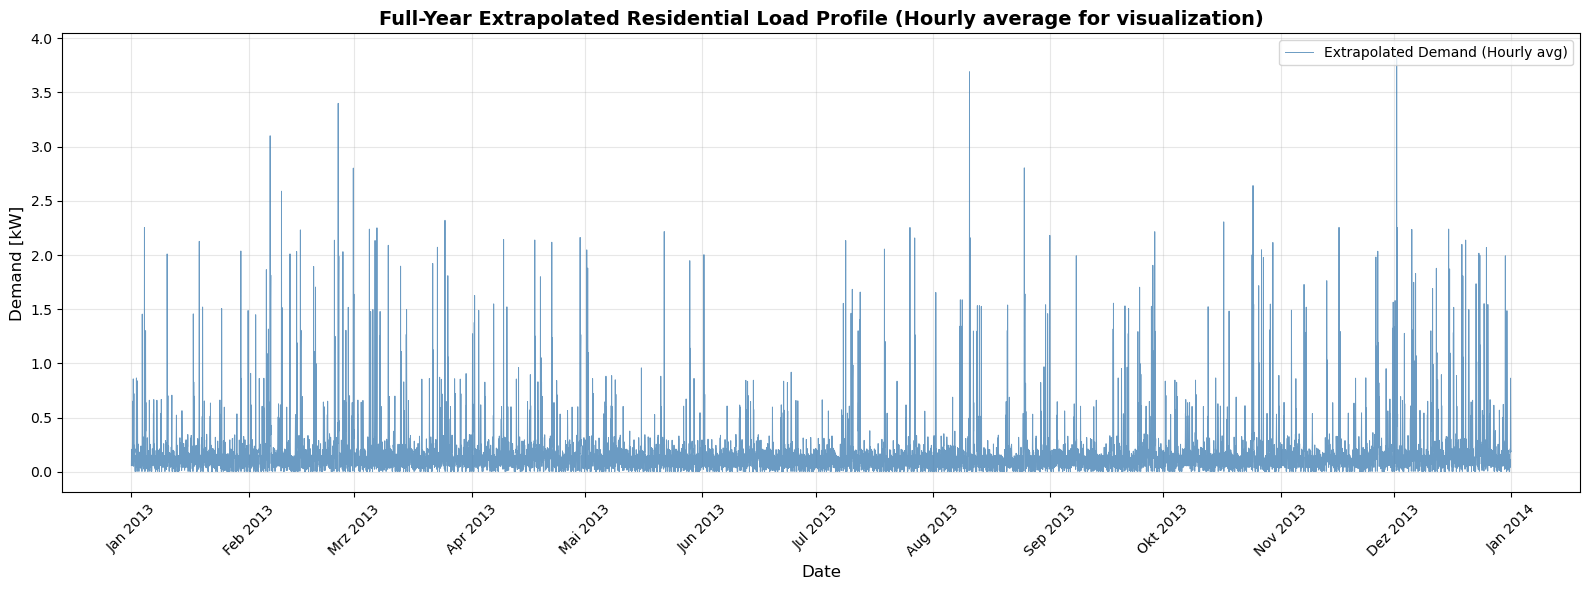

Extrapolated demand statistics (1-minute data):
  Min: 0.0000 kW
  Max: 5.3365 kW
  Mean: 0.1808 kW
  Std Dev: 0.3466 kW

Note: Plot shows hourly averages for visualization. Underlying 1-minute data is preserved.


In [66]:
# --- PLOT FULL-YEAR EXTRAPOLATED DEMAND ---
import matplotlib.dates as mdates

# Resample to hourly for better visualization (525,600 points -> 8,760 points)
# This prevents visual aliasing while preserving the actual demand patterns
df_demand_hourly = df_demand_1min_fullYear.resample('h').mean()

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(df_demand_hourly.index, df_demand_hourly['Demand_kW'], 
        color='steelblue', linewidth=0.7, alpha=0.8, label='Extrapolated Demand (Hourly avg)')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Demand [kW]', fontsize=12)
ax.set_title('Full-Year Extrapolated Residential Load Profile (Hourly average for visualization)', fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(True, which='both', alpha=0.3)

# Format X-axis with month labels
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Extrapolated demand statistics (1-minute data):")
print(f"  Min: {df_demand_1min_fullYear['Demand_kW'].min():.4f} kW")
print(f"  Max: {df_demand_1min_fullYear['Demand_kW'].max():.4f} kW")
print(f"  Mean: {df_demand_1min_fullYear['Demand_kW'].mean():.4f} kW")
print(f"  Std Dev: {df_demand_1min_fullYear['Demand_kW'].std():.4f} kW")
print(f"\nNote: Plot shows hourly averages for visualization. Underlying 1-minute data is preserved.")

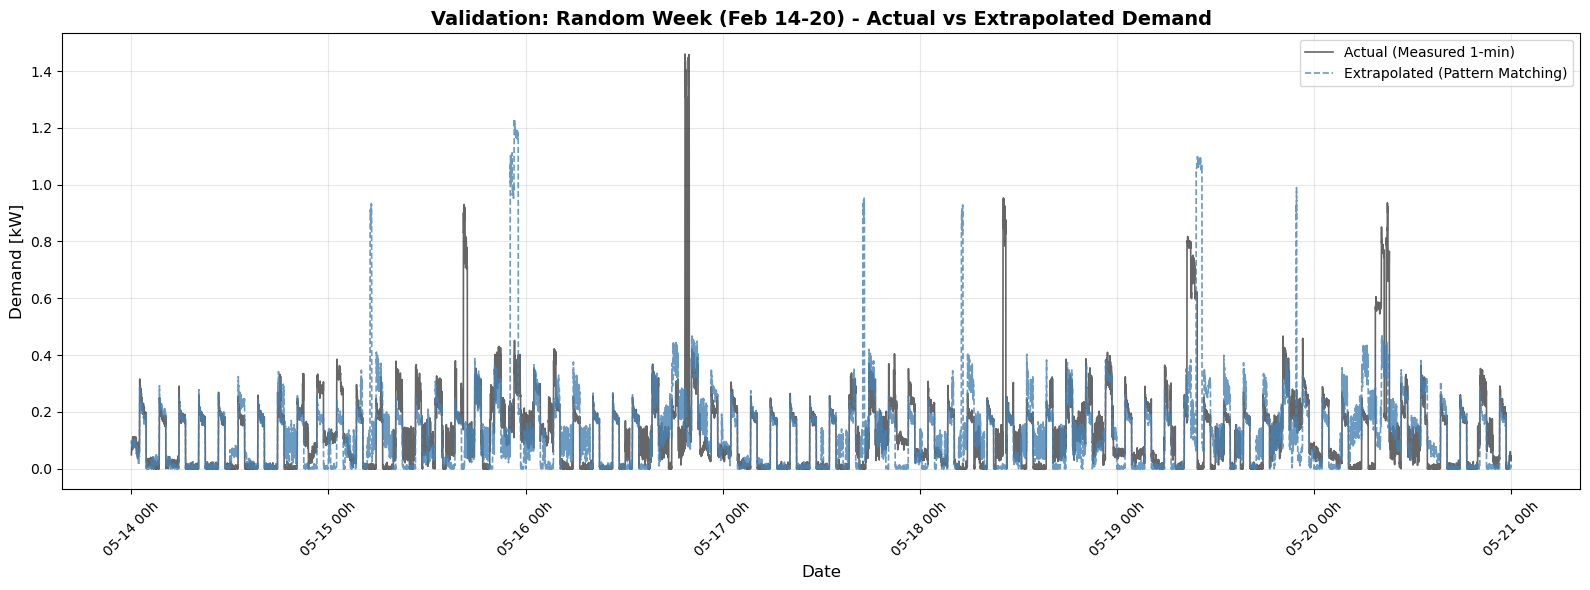

Statistics Comparison for Random Week (Feb 14-20):

Actual Demand:
  Mean: 0.1260 kW
  Std Dev: 0.1456 kW
  Min: 0.0000 kW
  Max: 1.4598 kW

Extrapolated Demand:
  Mean: 0.1250 kW
  Std Dev: 0.1518 kW
  Min: 0.0000 kW
  Max: 1.2317 kW


In [67]:
# --- VALIDATION: COMPARE RANDOM WEEK FROM ACTUAL DATA VS EXTRAPOLATED ---
import matplotlib.dates as mdates

# Load the full-year actual demand data (before filtering to 3 weeks)
df_demand_full = pd.read_csv(f"Data/hh_demand_true_{DATA}.csv")
df_demand_full['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_demand_full), freq='min')
df_demand_full.set_index('timestamp', inplace=True)

# Pick a random week that's NOT one of the training weeks
# Training weeks: Jan 10-16, Apr 10-16, Jul 10-16
# Let's pick: Feb 14-20 (Valentine's week)
test_week_start = '2013-05-14'
test_week_end = '2013-05-20'

# Extract the actual demand for this week
actual_week = df_demand_full.loc[test_week_start:test_week_end]

# Extract the extrapolated demand for the same week
extrapolated_week = df_demand_1min_fullYear.loc[test_week_start:test_week_end]

# Create comparison plot
fig, ax = plt.subplots(figsize=(16, 6))

# Plot actual demand (black)
ax.plot(actual_week.index, actual_week.iloc[:, 0], 
        color='black', alpha=0.6, linewidth=1.2, label='Actual (Measured 1-min)')

# Plot extrapolated demand (blue)
ax.plot(extrapolated_week.index, extrapolated_week['Demand_kW'], 
        color='steelblue', alpha=0.8, linewidth=1.2, linestyle='--', label='Extrapolated (Pattern Matching)')

ax.set_title(f'Validation: Random Week (Feb 14-20) - Actual vs Extrapolated Demand', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Demand [kW]', fontsize=12)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)

# Format X-axis
date_fmt = mdates.DateFormatter('%m-%d %Hh')
ax.xaxis.set_major_formatter(date_fmt)
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# Print statistics comparison
print("Statistics Comparison for Random Week (Feb 14-20):")
print(f"\nActual Demand:")
print(f"  Mean: {actual_week.iloc[:, 0].mean():.4f} kW")
print(f"  Std Dev: {actual_week.iloc[:, 0].std():.4f} kW")
print(f"  Min: {actual_week.iloc[:, 0].min():.4f} kW")
print(f"  Max: {actual_week.iloc[:, 0].max():.4f} kW")

print(f"\nExtrapolated Demand:")
print(f"  Mean: {extrapolated_week['Demand_kW'].mean():.4f} kW")
print(f"  Std Dev: {extrapolated_week['Demand_kW'].std():.4f} kW")
print(f"  Min: {extrapolated_week['Demand_kW'].min():.4f} kW")
print(f"  Max: {extrapolated_week['Demand_kW'].max():.4f} kW")

In [68]:
# --- EXPORT RESULTS ---
import os

# Create exports directory if it doesn't exist
export_dir = 'exports'
if not os.path.exists(export_dir):
    os.makedirs(export_dir)
    print(f"Created directory: {export_dir}")

# Export df_demand_1min_fullYear
demand_filename = f'{export_dir}/demand_1min_fullYear_Dataset_{DATA}.csv'
df_demand_1min_fullYear.to_csv(demand_filename)
print(f"Exported: {demand_filename}")
print(f"  Shape: {df_demand_1min_fullYear.shape}")
print(f"  File size: {os.path.getsize(demand_filename) / (1024*1024):.2f} MB")

# Export df_result (weather/irradiance/temperature data)
weather_filename = f'{export_dir}/weather_1min_fullYear_Dataset_{DATA}.csv'
df_result.to_csv(weather_filename)
print(f"\nExported: {weather_filename}")
print(f"  Shape: {df_result.shape}")
print(f"  File size: {os.path.getsize(weather_filename) / (1024*1024):.2f} MB")

print(f"\nAll files exported successfully to '{export_dir}/' directory!")

Exported: exports/demand_1min_fullYear_Dataset_A.csv
  Shape: (525600, 1)
  File size: 19.34 MB

Exported: exports/weather_1min_fullYear_Dataset_A.csv
  Shape: (525600, 2)
  File size: 25.54 MB

All files exported successfully to 'exports/' directory!
